In [1]:
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
! pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 19.8 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2


In [4]:
from datasets import load_dataset
import sentencepiece as spm

In [5]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from collections import Counter

In [6]:
# Global configuration
CONFIG = {
    "KAGGLE_WORKING_DIR": "/content/drive/MyDrive/Dataset/BiLSTM",
    "SEED": 42,
    "TOKENIZER_MODEL_PREFIX": os.path.join("/content/drive/MyDrive/Dataset/BiLSTM", "spm"),
    "TOKENIZER_MODEL_FILE": os.path.join("/content/drive/MyDrive/Dataset/BiLSTM", "spm.model"),
    "PREPROCESSED_DATA_PT_PATH": os.path.join("/content/drive/MyDrive/Dataset/BiLSTM", "preprocessed_tensors.pt"),
    "VOCAB_SIZE": 20000,
    "MAX_SEQ_LENGTH": 170,
    "TARGET_TOTAL_REVIEWS": 2_000_000,
    "TRAIN_SPLIT_RATIO": 0.70,
    "VAL_SPLIT_RATIO": 0.15,
    "TEST_SPLIT_RATIO": 0.15,
    "BATCH_SIZE": 128
}

os.makedirs(CONFIG["KAGGLE_WORKING_DIR"], exist_ok=True)

def set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["SEED"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

def save_pytorch_object(obj, path):
    torch.save(obj, path)

def load_pytorch_object(path):
    return torch.load(path)

Using device: cpu


In [7]:
# Function to process and extract specific columns from a dataset
def process_dataset(dataset_name, subset_name, columns):
    dataset = load_dataset(
        "McAuley-Lab/Amazon-Reviews-2023",
        subset_name, split="full",
        trust_remote_code=True
    )
    return dataset.to_pandas()[columns]

# Define the columns to keep
columns_to_keep = ["text", "rating"]

# Process datasets
beauty_df = process_dataset("Amazon-Reviews-2023", "raw_review_Beauty_and_Personal_Care", columns_to_keep)
movies_df = process_dataset("Amazon-Reviews-2023", "raw_review_Movies_and_TV", columns_to_keep)

# Concatenate DataFrames
combined_df = pd.concat([beauty_df, movies_df])

# Remove neutral reviews
combined_df = combined_df[combined_df["rating"] != 3]

# Remove empty reviews and NaN
combined_df = combined_df.dropna(subset=["text", "rating"])
combined_df = combined_df[combined_df["text"].str.strip() != ""]

# Drop exact duplicates (based on text and rating)
combined_df = combined_df.drop_duplicates(subset=["text", "rating"])

# Label sentiment: 0 for negative (<3), 1 for positive (>3)
combined_df["sentiment"] = combined_df["rating"].apply(lambda x: 0 if x < 3 else 1)

# Downsample to 1M negative and 1M positive reviews for perfect balance
neg_df = combined_df[combined_df["sentiment"] == 0]
pos_df = combined_df[combined_df["sentiment"] == 1]

if len(neg_df) < 1_000_000 or len(pos_df) < 1_000_000:
    print(f"Error: Not enough samples to form a balanced dataset. Found {len(neg_df)} negative and {len(pos_df)} positive.")
    balanced_df = pd.DataFrame()
else:
    neg_df = neg_df.sample(n=1_000_000, random_state=42)
    pos_df = pos_df.sample(n=1_000_000, random_state=42)
    balanced_df = pd.concat([neg_df, pos_df]).sample(frac=1, random_state=42).reset_index(drop=True)

    all_texts_raw = balanced_df["text"].tolist()
    all_ratings_raw = balanced_df["rating"].tolist()
    all_labels = balanced_df["sentiment"].tolist()

    print(f"Total reviews available for processing: {len(balanced_df)}")
    print(f"Negative: {sum(balanced_df['sentiment']==0)}, Positive: {sum(balanced_df['sentiment']==1)}")


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/30.3k [00:00<?, ?B/s]

Amazon-Reviews-2023.py:   0%|          | 0.00/39.6k [00:00<?, ?B/s]

Beauty_and_Personal_Care.jsonl:   0%|          | 0.00/11.0G [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

Movies_and_TV.jsonl:   0%|          | 0.00/8.39G [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

Total reviews available for processing: 2000000
Negative: 1000000, Positive: 1000000


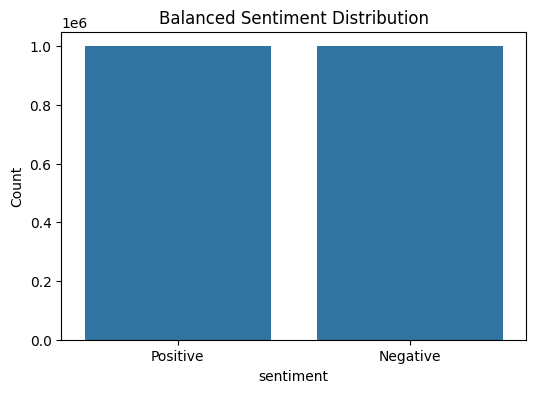

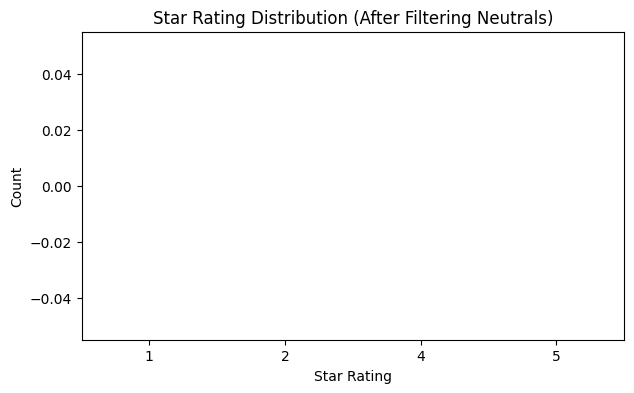

In [9]:
# Plot sentiment distribution
plt.figure(figsize=(6,4))
sns.countplot(x=balanced_df["sentiment"].map({0: "Negative", 1: "Positive"}))
plt.title("Balanced Sentiment Distribution")
plt.ylabel("Count")
plt.savefig("/content/drive/MyDrive/Dataset/BiLSTM/sentiment_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot star rating distribution (after filtering neutrals)
plt.figure(figsize=(7,4))
sns.countplot(data=balanced_df, x='rating', order=[1,2,4,5])
plt.title('Star Rating Distribution (After Filtering Neutrals)')
plt.xlabel('Star Rating')
plt.ylabel('Count')
plt.savefig("/content/drive/MyDrive/Dataset/BiLSTM/star_rating_distribution", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
combined_df = combined_df.drop(columns=["rating"])

In [11]:
combined_df.head()

,text,sentiment
0,Opened the package & instant migraine. I canno...,0
1,Tops the list for worst purchase. Tried these ...,0
2,Bought this for my granddaughter. Her entire ...,1
3,These are extremely dull and will wreck your n...,0
5,I don't often leave negative feedback about pr...,0


In [12]:
combined_df.to_csv('/content/drive/MyDrive/Dataset/BiLSTM/dataset.csv', index= False)

In [13]:
# Cell: SentencePiece Tokenizer Training

if not os.path.exists(CONFIG["TOKENIZER_MODEL_FILE"]):
    corpus_path = os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "corpus.txt")
    with open(corpus_path, "w", encoding="utf-8") as f:
        for line in all_texts_raw:
            f.write(line.replace("\n", " ") + "\n")
    spm.SentencePieceTrainer.Train(
        f"--input={corpus_path} --model_prefix={CONFIG['TOKENIZER_MODEL_PREFIX']} "
        f"--vocab_size={CONFIG['VOCAB_SIZE']} --pad_id=0 --unk_id=1 --bos_id=2 --eos_id=3 --model_type=unigram"
    )

sp = spm.SentencePieceProcessor(model_file=CONFIG["TOKENIZER_MODEL_FILE"])
PAD_TOKEN_ID = sp.pad_id()
print(f"PAD_TOKEN_ID: {PAD_TOKEN_ID}")


PAD_TOKEN_ID: 0


In [15]:
# Cell: Tokenization, Padding, and Token Length Visualization
# --- Tokenization, Padding, and Length Calculation (biLSTM style) ---
def tokenize_and_pad(texts, sp, max_len, pad_token_id):
    input_ids, lengths = [], []
    for text in texts:
        ids = sp.encode(text, out_type=int)
        lengths.append(min(len(ids), max_len))
        ids = ids[:max_len]
        if len(ids) < max_len:
            ids += [pad_token_id]*(max_len - len(ids))
        input_ids.append(ids)
    return (
        torch.tensor(input_ids, dtype=torch.long),
        lengths
    )

input_ids, lengths = tokenize_and_pad(
    all_texts_raw, sp, CONFIG["MAX_SEQ_LENGTH"], PAD_TOKEN_ID
)
labels_tensor = torch.tensor(all_labels, dtype=torch.float32)
lengths_tensor = torch.tensor(lengths, dtype=torch.long)


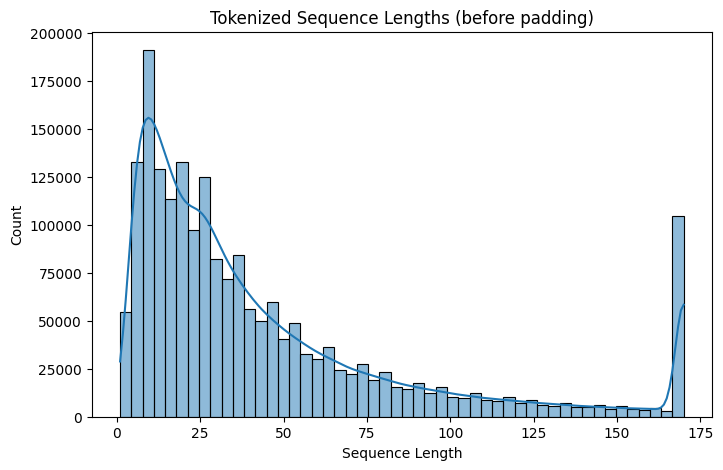

Mean: 45.2, Median: 29.0, 90th percentile: 112.0, 95th percentile: 170.0


In [16]:
# Visualize token length distribution
plt.figure(figsize=(8,5))
sns.histplot(lengths, bins=50, kde=True)
plt.title("Tokenized Sequence Lengths (before padding)")
plt.xlabel("Sequence Length")
plt.ylabel("Count")
plt.savefig("/content/drive/MyDrive/Dataset/BiLSTM/sequence_lengths.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mean: {np.mean(lengths):.1f}, Median: {np.median(lengths)}, 90th percentile: {np.percentile(lengths, 90)}, 95th percentile: {np.percentile(lengths, 95)}")

In [17]:
# Save tensors for memory efficiency
torch.save(input_ids, os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "input_ids.pt"))
torch.save(labels_tensor, os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "labels_tensor.pt"))
torch.save(lengths_tensor, os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "lengths_tensor.pt"))
print("Saved input_ids, labels_tensor, and lengths_tensor.")

Saved input_ids, labels_tensor, and lengths_tensor.


In [18]:
# --- Stratified Split (indices) ---
train_idx, temp_idx, train_y, temp_y = train_test_split(
    np.arange(len(labels_tensor)), labels_tensor.tolist(),
    test_size=CONFIG["VAL_SPLIT_RATIO"] + CONFIG["TEST_SPLIT_RATIO"],
    stratify=labels_tensor.tolist(),
    random_state=CONFIG["SEED"]
)
val_idx, test_idx, _, _ = train_test_split(
    temp_idx, temp_y,
    test_size=0.5,
    stratify=temp_y,
    random_state=CONFIG["SEED"]
)

# Save split indices for later use
np.save(os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "train_idx.npy"), train_idx)
np.save(os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "val_idx.npy"), val_idx)
np.save(os.path.join(CONFIG["KAGGLE_WORKING_DIR"], "test_idx.npy"), test_idx)
print("Saved train/val/test indices.")


Saved train/val/test indices.
